# Anomaly detection evaluation (AI-008)

Four transparent **rules** and an **Isolation Forest** score every stock transaction. Eight anomalies were
injected into the synthetic ledger with ground-truth labels (`anomaly-labels.json`). The labels are used
**only here**: they never reach training, rule thresholds or the contamination rate (fixed at 0.5%
beforehand). Rules, model and the combination are reported separately.

**Read this first.** The injected anomalies were designed with the same ideas the rules encode (outside
business hours, a big negative adjustment), so the rules catch them *by construction*. The model's
result is the informative part, and it is shown without flattering it.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent                      # ai-service/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

ACTUAL, BASELINE, ML, SELECTED = "#444444", "#0072B2", "#D55E00", "#009E73"   # colour-blind safe
FIXTURES = ROOT / "tests" / "fixtures"

In [2]:
import json
from app.anomaly.evaluate import evaluate_anomaly_detection, load_labels
from app.anomaly.model import fit_anomaly_model, score_ledger
from app.data.sources import CsvSource

source = CsvSource(FIXTURES)
ledger, products, warehouses = source.ledger(), source.products(), source.warehouses()
labels = load_labels(FIXTURES / "anomaly-labels.json")
profiles = json.loads((FIXTURES / "scenarios.json").read_text())

model = fit_anomaly_model(ledger)
scored = score_ledger(model, ledger)
evaluation = evaluate_anomaly_detection(scored, ledger, products, warehouses, labels)
print(f"{len(scored):,} transactions scored | {int(scored.flagged.sum())} flagged "
      f"(rules {int(scored.rule_flag.sum())}, model {int(scored.model_flag.sum())}, both {int((scored.source == 'BOTH').sum())}) | {len(evaluation.labelled)} injected anomalies")

2,978 transactions scored | 33 flagged (rules 19, model 14, both 0) | 8 injected anomalies


## 1. Detection by anomaly type

In [3]:
by_type = evaluation.by_type.set_index("anomaly_type")
table = pd.DataFrame({
    "injected": by_type["injected"],
    "rules": by_type["rules_detected"].astype(int).astype(str) + " / " + by_type["injected"].astype(str),
    "model": by_type["model_detected"].astype(int).astype(str) + " / " + by_type["injected"].astype(str),
    "combined": by_type["combined_detected"].astype(int).astype(str) + " / " + by_type["injected"].astype(str),
})
table.loc["ALL"] = [by_type["injected"].sum()] + [f"{int(by_type[c].sum())} / {int(by_type['injected'].sum())}" for c in ("rules_detected", "model_detected", "combined_detected")]
table

,injected,rules,model,combined
anomaly_type,,,,
DUPLICATE_ISSUE,1,0 / 1,0 / 1,0 / 1
MANUAL_RECEIPT,1,1 / 1,0 / 1,1 / 1
NEGATIVE_ADJUSTMENT,2,2 / 2,0 / 2,2 / 2
OFF_HOURS_ISSUE,2,2 / 2,0 / 2,2 / 2
SPIKE_ISSUE,2,1 / 2,0 / 2,1 / 2
ALL,8,6 / 8,0 / 8,6 / 8


In [4]:
overall = evaluation.overall.set_index("detector")
overall = overall[["true_positives", "missed", "false_positives", "precision", "recall"]]
overall.round(3)

,true_positives,missed,false_positives,precision,recall
detector,,,,,
rules,6,2,13,0.316,0.75
model,0,8,14,0.000,0.00
combined,6,2,27,0.182,0.75


In [5]:
r = evaluation.ranking
print(f"Model score, threshold-free: ROC-AUC {r['roc_auc']:.3f}; average precision {r['average_precision']:.3f} "
      f"vs {r['baseline_average_precision']:.4f} for a random ranking ({r['average_precision'] / r['baseline_average_precision']:.0f}x).")
print("Labelled anomalies found among the model's top K:", {f"top {k}": f"{v} of {r['labelled']}" for k, v in r["recall_at_k"].items()})
flags = scored[scored["model_flag"]]
print(f"At the 0.5% operating point the model catches {int(evaluation.labelled['model'].sum())} of {len(evaluation.labelled)} injected anomalies; "
      f"its {len(flags)} flags are all {', '.join(sorted(flags['type'].unique()))} rows (large goods receipts, the opening stock).")

Model score, threshold-free: ROC-AUC 0.849; average precision 0.035 vs 0.0027 for a random ranking (13x).
Labelled anomalies found among the model's top K: {'top 10': '0 of 8', 'top 20': '0 of 8', 'top 50': '2 of 8'}
At the 0.5% operating point the model catches 0 of 8 injected anomalies; its 14 flags are all RECEIPT rows (large goods receipts, the opening stock).


## 2. Every injected anomaly

In [6]:
evaluation.labelled[["label", "anomaly_type", "sku", "expected_detection", "rules", "model", "combined", "model_score", "model_rank", "rule_codes"]].round(3)

,label,anomaly_type,sku,expected_detection,rules,model,combined,model_score,model_rank,rule_codes
0,A-01,SPIKE_ISSUE,SYN-ELE-005,BOTH,True,False,True,0.987,38,R2
1,A-02,NEGATIVE_ADJUSTMENT,SYN-BRK-004,RULE,True,False,True,0.967,97,R1
2,A-03,OFF_HOURS_ISSUE,SYN-ENG-006,RULE,True,False,True,0.315,2039,R3
3,A-04,NEGATIVE_ADJUSTMENT,SYN-BRK-006,RULE,True,False,True,0.981,58,R1
4,A-05,SPIKE_ISSUE,SYN-ELE-002,BOTH,False,False,False,0.963,109,
5,A-06,DUPLICATE_ISSUE,SYN-BRK-003,MODEL,False,False,False,0.961,116,
6,A-07,MANUAL_RECEIPT,SYN-ENG-006,BOTH,True,False,True,0.987,39,R4
7,A-08,OFF_HOURS_ISSUE,SYN-ELE-005,RULE,True,False,True,0.624,1119,R3


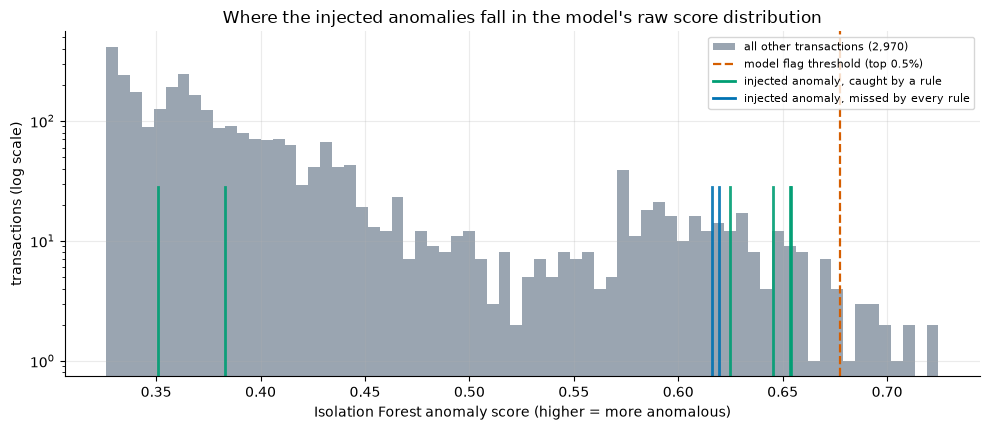

In [7]:
from app.anomaly.features import compute_features
feats = compute_features(ledger, model.stats, 6)
raw = pd.Series(model.raw_scores(feats), index=feats["id"])          # Isolation Forest score: higher = more anomalous
threshold = np.quantile(model.train_scores, 1 - model.contamination)
labelled = evaluation.labelled.set_index("id")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(raw[~raw.index.isin(labelled.index)], bins=70, color="#9aa5b1", label=f"all other transactions ({len(raw) - len(labelled):,})")
ax.axvline(threshold, color=ML, ls="--", lw=1.6, label="model flag threshold (top 0.5%)")
for row_id, row in labelled.iterrows():
    ax.axvline(raw[row_id], ymax=0.55, color=SELECTED if row["rules"] else BASELINE, lw=2, alpha=0.9)
ax.plot([], [], color=SELECTED, lw=2, label="injected anomaly, caught by a rule")
ax.plot([], [], color=BASELINE, lw=2, label="injected anomaly, missed by every rule")
ax.set_yscale("log"); ax.set_xlabel("Isolation Forest anomaly score (higher = more anomalous)"); ax.set_ylabel("transactions (log scale)")
ax.set_title("Where the injected anomalies fall in the model's raw score distribution")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

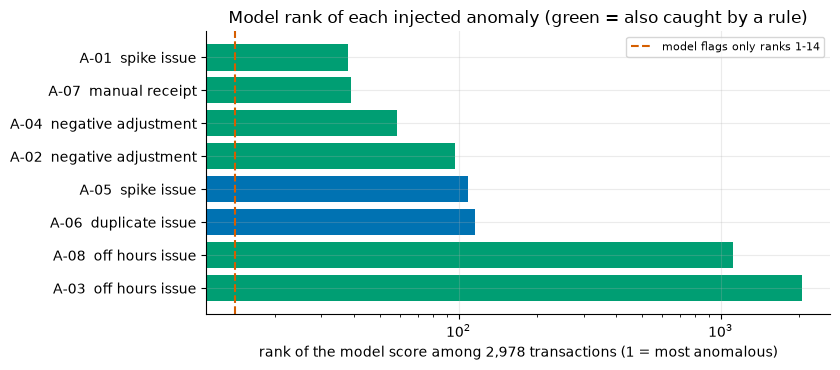

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
data = evaluation.labelled.sort_values("model_rank", ascending=False)
colors = [SELECTED if r else BASELINE for r in data["rules"]]
ax.barh(data["label"] + "  " + data["anomaly_type"].str.replace("_", " ").str.lower(), data["model_rank"], color=colors)
ax.axvline(int(len(scored) * 0.005), color=ML, ls="--", label="model flags only ranks 1-%d" % int(len(scored) * 0.005))
ax.set_xscale("log"); ax.set_xlabel(f"rank of the model score among {len(scored):,} transactions (1 = most anomalous)")
ax.set_title("Model rank of each injected anomaly (green = also caught by a rule)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 2b. Why the model misses the off-hours events

An Isolation Forest isolates points by random splits on features. In the training data only a handful of
transactions are outside business hours, so in most trees' random samples that feature is constant and
cannot be split on: such events are not isolated quickly and look ordinary. The rule covers them directly,
which is the point of having both layers.

In [9]:
off = (feats["off_hours_distance"] > 0).to_numpy()
injected = feats["id"].isin(evaluation.labelled["id"]).to_numpy()
print(f"{int(off.sum())} of {len(feats):,} transactions are outside business hours ({100 * off.mean():.2f}%); "
      f"{int((off & injected).sum())} of them are injected anomalies.")

# the hypothesis, checked: how many trees ever saw an off-hours row in their random sample?
saw = np.mean([off[idx].any() for idx in model.forest.estimators_samples_])
print(f"Only {100 * saw:.0f}% of the {len(model.forest.estimators_samples_)} trees had an off-hours transaction in their sample; "
      f"in the other {100 * (1 - saw):.0f}% that feature is constant and cannot isolate anything.")

2 of 2,978 transactions are outside business hours (0.07%); 2 of them are injected anomalies.
Only 15% of the 300 trees had an off-hours transaction in their sample; in the other 85% that feature is constant and cannot isolate anything.


## 3. False positives: what the combined detector flags that is not labelled

In [10]:
from app.anomaly.evaluate import categorize_false_positives, is_data_artefact
steered = {sku for sku, p in profiles["profiles"].items() if p in profiles["steeredProfiles"]}
fp = categorize_false_positives(evaluation.false_positives, ledger, labels, steered)
summary = fp.groupby(["source", "type", "likely_cause"]).size().rename("flags").reset_index().sort_values("flags", ascending=False)
print(f"{len(fp)} false positives out of {int(scored.flagged.sum())} flags "
      f"-> precision {evaluation.overall.set_index('detector').loc['combined', 'precision']:.2f}")
summary

27 false positives out of 33 flags -> precision 0.18


,source,type,likely_cause,flags
4,RULE,ISSUE,ordinary large movement (natural tail of the d...,10
1,MODEL,RECEIPT,"opening stock received on day 1 (a one-off, la...",8
0,MODEL,RECEIPT,large goods receipt (a legitimate replenishmen...,6
3,RULE,ISSUE,last-day trim: the generator landing a demo st...,2
2,RULE,ADJUSTMENT,ordinary large movement (natural tail of the d...,1


In [11]:
natural = fp[~fp["likely_cause"].map(is_data_artefact)]
print(f"Setting aside the flags caused by how the synthetic data was built ({len(fp) - len(natural)}), {len(natural)} flags remain:")
natural["likely_cause"].value_counts()

Setting aside the flags caused by how the synthetic data was built (10), 17 flags remain:


likely_cause
ordinary large movement (natural tail of the demand distribution)    11
large goods receipt (a legitimate replenishment order)                6
Name: count, dtype: int64

## 4. What this does and does not show

* **Rules catch what they were written for.** Off-hours events, large negative adjustments and large manual
  receipts are found because the injected anomalies match the rules, not because the system discovered anything.
* **The model adds little at its operating point on this data.** It ranks the labelled rows well above chance
  (see ROC-AUC and average precision) but not into the top 0.5%, and its flags are dominated by large legitimate
  receipts. Duplicates, which were deliberately left to it, are missed.
* **Rule R2 also fires on ordinary tail events.** Daily demand is Poisson-like, so now and then one issue holds a
  whole busy day's units; a robust z-score on such skewed counts is not conservative. Thresholds were fixed
  before looking at the labels and are not retuned here.
* **Eight labels** are far too few to tune anything, and tuning on them would only overfit.
* Real anomalies are rarer, subtler and unlabelled; precision on real data will differ.